# 02 · RQ1: Learn payment prediction one step at a time
**DSC 411/511 graduate project · Venkat Repaka and Ritik Gaire**

**Question:** Can policy, building and external event information predict positive building payments?

Notebook 01 found skewed payments, rare large buildings, repeated rain information and a few dominant storms. We now turn each observation into a model comparison.

**Course links:** lecture 03 motivates transformations; lecture 04 motivates feature selection and PCA; lecture 07 motivates pipelines, leakage checks and validation. Forests and boosting extend the course's tree ideas. We explain those additions rather than treating them as unexplained software options.

**Learning path:** constant guess → linear models → tree depth → ensembles → stronger validation → fewer columns → external sources → coverage normalization → later-year and storm checks.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

task = 'regression'

df = load_joined()

## 1. Define exactly what we predict
We use claims with positive recorded building payments. This answers the amount **when a positive payment is recorded**, not whether any claim will receive money. We keep the same fitting and validation years for all candidates.

In [2]:
d = df[df.amountPaidOnBuildingClaim > 0].copy()

fit = d.loss_year <= 2021
valid = d.loss_year.between(2022,2023)
train = d.loss_year <= 2023
test = d.loss_year >= 2024
ydev = d.amountPaidOnBuildingClaim
y = ydev.copy()

display(pd.Series({'fit 2020–2021':fit.sum(),'validate 2022–2023':valid.sum(),
                   'refit 2020–2023':train.sum(),'evaluate 2024–2025':test.sum()}).to_frame('claims'))

,claims
fit 2020–2021,58740
validate 2022–2023,61032
refit 2020–2023,119772
evaluate 2024–2025,93194


### 1.1 First establish a useful baseline
A mean prediction targets squared error; a median prediction targets absolute error. Neither uses building information. Every added model must show what it improves over these simple guesses.

In [3]:
baselines={
 'fitting mean':np.full(valid.sum(),ydev[fit].mean()),
 'fitting median':np.full(valid.sum(),ydev[fit].median())}
baseline_table=pd.DataFrame({name:regression_scores(ydev[valid],p) for name,p in baselines.items()}).T
display(baseline_table.round(2));save_table(baseline_table,'02_development_baselines')

,R2,MAE $,median error $
fitting mean,-0.060,"74,673.700","35,243.570"
fitting median,-0.120,"78,689.720","27,984.020"


**How to read the next steps.** R² rewards reducing large squared mistakes. MAE is the average dollar error. Median error describes a typical claim. A candidate can improve one and weaken another. We select by validation R², then show the trade-off in the other measures.

## 2. Build a comparison tool without hiding the model sequence
This small function fits one declared candidate and adds its result to a growing table. Preprocessing is inside the model pipeline, so a validation claim cannot set its own replacement value. The comparison function is bookkeeping; the next sections name and explain each experiment.

In [4]:
import time
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import Ridge
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.decomposition import PCA

rows=[]
validation_predictions={}

def try_candidates(candidates):
    for features,family in candidates:
        started=time.monotonic()
        cols=FEATURE_SETS[features]
        model=candidate_model(d[cols],task,family)
        ix=d.index[fit]
        if family=='forest' and len(ix)>80000:
            ix=d.loc[ix].sample(80000,random_state=SEED).index
        model.fit(d.loc[ix,cols],ydev.loc[ix])
        pred=np.maximum(model.predict(d.loc[valid,cols]),0)
        key=features+' | '+family
        validation_predictions[key]=pred
        scores=regression_scores(ydev[valid],pred)
        rows.append({'candidate':key,'features':features,'family':family,**scores})
        print(f'Finished {key} in {time.monotonic()-started:.1f} seconds',flush=True)
    table=pd.DataFrame(rows).set_index('candidate').sort_values('R2',ascending=False)
    display(table.round(3))
    return table

### 2.1 Read the first linear model directly
A linear model combines weighted inputs. One-hot encoding handles category labels. Ridge adds a penalty to keep weights from becoming too large, especially when columns overlap.

We test ordinary dollar prediction and a log-payment target. The latter gives less fitting weight to the very largest payments; conversion back to dollars can still leave a biased or weak dollar prediction.

In [5]:
# These are the two model definitions behind the first comparison.
dollar_linear=make_pipeline(prepare(d[CORE],scale=True),Ridge(alpha=100))
log_linear=make_pipeline(prepare(d[CORE],scale=True),
    TransformedTargetRegressor(regressor=Ridge(alpha=100),func=np.log1p,inverse_func=np.expm1))
linear_results=try_candidates([('core','dollar ridge'),('core','linear')])

Finished core | dollar ridge in 0.3 seconds


Finished core | linear in 0.3 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core | linear,core,linear,-0.056,"73,507.585","28,078.624"


**Keep or discard?** Compare both rows with the mean and median baselines. A negative R² is a warning about this fitted model and period, not proof that every linear method is useless. We keep these results as references rather than deleting the weak model from the report.

**Checkpoint · What the result changes**

Dollar ridge gives validation R² **0.033**, while log-target ridge gives **-0.056** after conversion to dollars. A log transformation did not automatically solve this task. We keep both as baselines and next allow nonlinear groups.

## 3. Let a tree learn nonlinear groups
A shallow tree asks a few questions, such as whether coverage is above a value. A deeper tree can fit narrower groups and can also fit noise. We compare depths 2, 6 and 12 on the same validation years.

Finished core | tree depth 2 in 0.3 seconds


Finished core | tree depth 6 in 0.5 seconds


Finished core | tree depth 12 in 0.6 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core | tree depth 12,core,tree depth 12,0.020,"69,116.280","29,656.173"
core | tree depth 6,core,tree depth 6,0.005,"71,481.819","27,819.663"
core | linear,core,linear,-0.056,"73,507.585","28,078.624"


,fitting R2,validation R2
depth,,
2,0.168,0.039
6,0.276,0.005
12,0.361,0.020


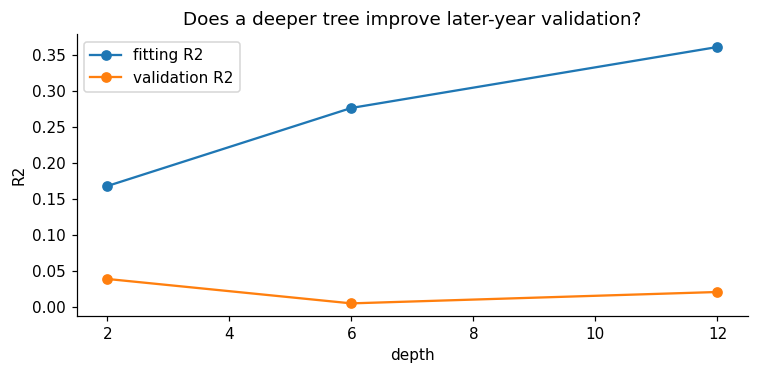

In [6]:
tree_results=try_candidates([('core','tree depth 2'),('core','tree depth 6'),('core','tree depth 12')])
train_rows=[]
for depth in [2,6,12]:
    model=candidate_model(d[CORE],task,f'tree depth {depth}').fit(d.loc[fit,CORE],ydev[fit])
    train_rows.append({'depth':depth,'fitting R2':r2_score(ydev[fit],model.predict(d.loc[fit,CORE])),
                       'validation R2':r2_score(ydev[valid],model.predict(d.loc[valid,CORE]))})
depth_table=pd.DataFrame(train_rows).set_index('depth');display(depth_table.round(3))
depth_table.plot(marker='o',figsize=(7,3.5),title='Does a deeper tree improve later-year validation?')
plt.ylabel('R2');plt.tight_layout();plt.show()

### 3.1 See the first decisions
We draw only the first two levels. A long tree would be difficult to read. Node predictions are payment averages among the fitting claims reaching that node.

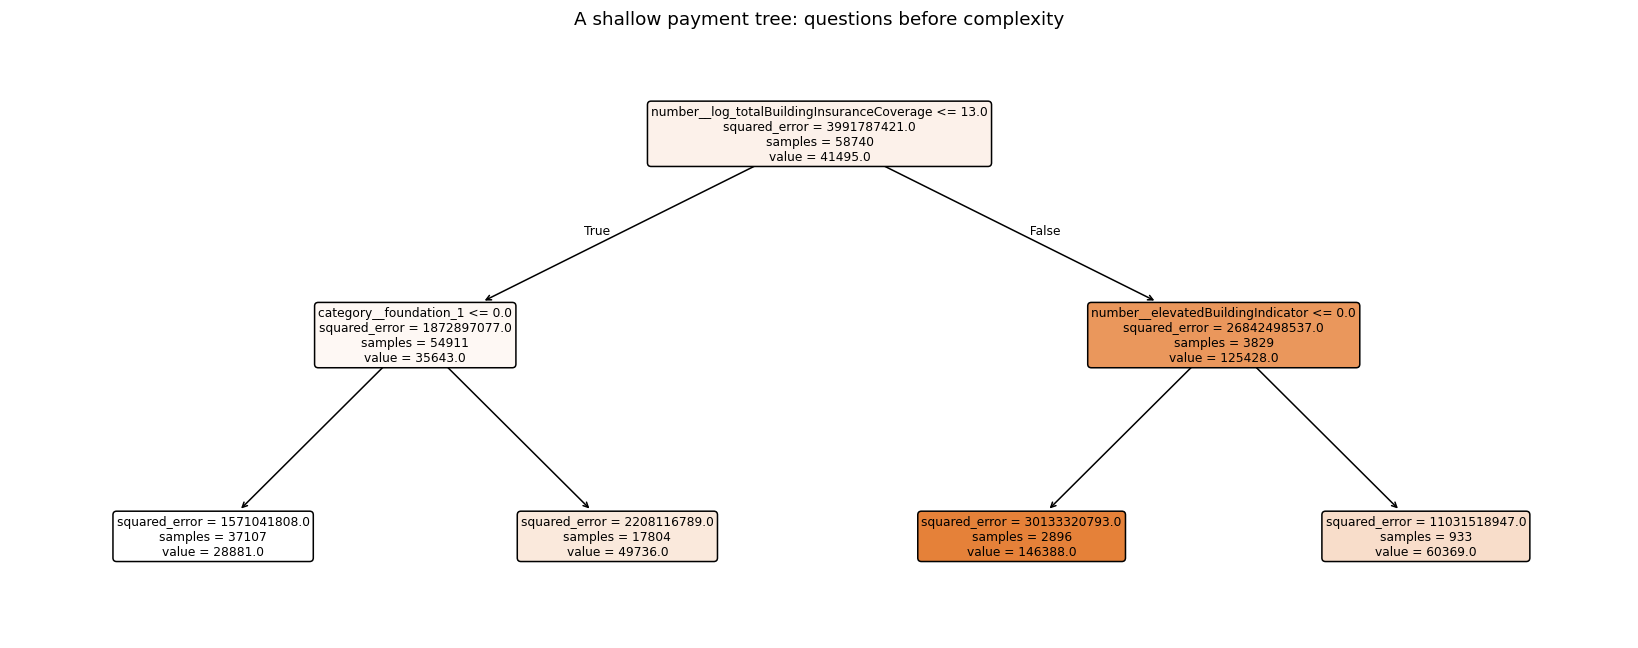

In [7]:
shallow=make_pipeline(prepare(d[CORE]),DecisionTreeRegressor(max_depth=2,min_samples_leaf=30,random_state=SEED)).fit(d.loc[fit,CORE],ydev[fit])
feature_names=shallow.steps[0][1].get_feature_names_out()
plt.figure(figsize=(15,6))
plot_tree(shallow.steps[-1][1],feature_names=feature_names,filled=True,rounded=True,fontsize=8,precision=0)
plt.title('A shallow payment tree: questions before complexity');plt.tight_layout();plt.show()

**Lesson.** A fitting score can rise while validation does not. We therefore keep the validation comparison, not the deepest tree by default. Next we reduce the dependence on one tree by averaging or combining trees.

**Checkpoint · What the result changes**

Tree R² is **0.039** at depth 2, **0.005** at depth 6, and **0.020** at depth 12. More depth did not steadily improve validation. Next we combine trees rather than assuming the deepest single tree is best.

## 4. Compare ensembles with the simpler models
A forest averages many trees. Boosting builds small trees one after another to reduce remaining mistakes. These are project extensions to the lecture's single tree. We test a smaller regularized boosting model and a more flexible one to check both underfitting and overfitting.

### Settings are declared, not hidden

| Model | Main settings | Purpose of the comparison |
|---|---|---|
| Forest | 120 trees, depth at most 18, at least 15 cases per leaf; 60% bootstrap sample per tree | Average many trees while limiting very small leaves |
| Core boosting | 140 rounds, at most 15 leaves, learning rate 0.06, regularization 10 | A moderate nonlinear reference |
| Smaller boosting | 200 rounds, at most 7 leaves, regularization 100 | Test stronger smoothing |
| Flexible boosting | 300 rounds, at most 31 leaves, regularization 0 | Test whether the moderate model is too restricted |
| Coverage-share boosting | 220 rounds, at most 15 leaves, regularization 10 | Test a relative payment target |

Boosting uses at least 50 cases per leaf. Dollar and share regressions use a nonnegative Poisson-loss model; this is a modeling choice for the mean, not a claim that dollar amounts are event counts. The full repeatable definitions are in `project_utils.py`. We compare these declared settings rather than claiming an exhaustive search.

In [8]:
ensemble_results=try_candidates([('core','forest'),('core','boosting'),('core','small boosting'),('core','flexible boosting')])

Finished core | forest in 4.5 seconds


Finished core | boosting in 10.0 seconds


Finished core | small boosting in 10.1 seconds


Finished core | flexible boosting in 24.1 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | small boosting,core,small boosting,0.042,"66,731.056","28,147.403"
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | boosting,core,boosting,0.038,"66,657.925","27,761.824"
core | forest,core,forest,0.034,"68,190.709","28,768.161"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core | tree depth 12,core,tree depth 12,0.020,"69,116.280","29,656.173"
core | flexible boosting,core,flexible boosting,0.018,"67,316.413","27,622.510"
core | tree depth 6,core,tree depth 6,0.005,"71,481.819","27,819.663"
core | linear,core,linear,-0.056,"73,507.585","28,078.624"


### 4.1 Check whether random rows make the problem look easier
Following lecture 07, we compare three-fold shuffled row validation with three-fold event-separated validation on the same 20,000 fitting-period claims. All preprocessing is repeated inside each fold. This diagnostic uses no 2024–2025 outcomes.

In [9]:
cv_sample=d.loc[fit].sample(min(20000,fit.sum()),random_state=SEED)
event_groups=cv_sample.floodEvent.fillna('unnamed-'+cv_sample.loss_year.astype(str))
cv_model=candidate_model(cv_sample[CORE],task,'boosting')
random_scores=cross_val_score(cv_model,cv_sample[CORE],cv_sample.amountPaidOnBuildingClaim,
    cv=KFold(3,shuffle=True,random_state=SEED),scoring='r2')
group_scores=cross_val_score(cv_model,cv_sample[CORE],cv_sample.amountPaidOnBuildingClaim,
    cv=GroupKFold(3),groups=event_groups,scoring='r2')
cv_table=pd.DataFrame({'random rows':random_scores,'separate events':group_scores})
display(cv_table.round(3));display(cv_table.agg(['mean','std']).round(3))
save_table(cv_table,'02_row_vs_event_cv')

,random rows,separate events
0,0.329,0.166
1,0.315,0.244
2,0.327,0.213


,random rows,separate events
mean,0.324,0.208
std,0.008,0.040


**Decision.** The comparison shows how the evaluation question changes. Event separation asks a harder question and can have unstable scores when a few storms dominate. We keep chronological evaluation as the main later-year check. A random-row score is a diagnostic, not the final claim about future storms.

**Checkpoint · What the result changes**

Core boosting gives R² **0.038**, the forest **0.034**, and more flexible boosting **0.018**. These results do not support a simple “more complexity is better” conclusion. Next we change the representation.

## 5. Can fewer columns improve prediction? Start with the lecture 04 filters
We first inspect near-constant columns and correlated pairs using fitting data only. A feature's high variance does not prove usefulness, and a low-variance category may still describe rare buildings.

In [10]:
fit_preparation=prepare(d[CORE],scale=True).fit(d.loc[fit,CORE])
Zfit=fit_preparation.transform(d.loc[fit,CORE])
encoded_names=fit_preparation.get_feature_names_out()
variances=pd.Series(Zfit.var(axis=0),index=encoded_names)
print('Encoded columns:',len(encoded_names),'constant columns:',variances.le(1e-12).sum())
print('Lowest variance columns:');display(variances.sort_values().head(10).to_frame('variance'))
corr=pd.DataFrame(Zfit,columns=encoded_names).corr().abs()
pairs=corr.where(np.triu(np.ones(corr.shape,dtype=bool),k=1)).stack().sort_values(ascending=False)
display(pairs[pairs>.9].head(12).to_frame('absolute fitting correlation'))

Encoded columns: 101 constant columns: 0
Lowest variance columns:


,variance
category__occupancy_19,0.000
category__numberOfFloorsInTheInsuredBuilding_6,0.000
category__state_MT,0.000
category__state_ID,0.000
category__state_SD,0.000
category__state_ME,0.000
category__state_NH,0.000
category__state_UT,0.000
category__state_VT,0.000
category__state_NE,0.000


,,absolute fitting correlation
number__missingindicator_log_deductible_usd,category__numberOfFloorsInTheInsuredBuilding_unknown,0.935
number__missingindicator_building_age,category__numberOfFloorsInTheInsuredBuilding_unknown,0.904


### 5.1 Read the PCA scree curve before using components
PCA finds directions of large input variation, not directions that best predict payment. Numeric scaling and encoding are fitted on the fitting years. The two-component plot is only a partial view.

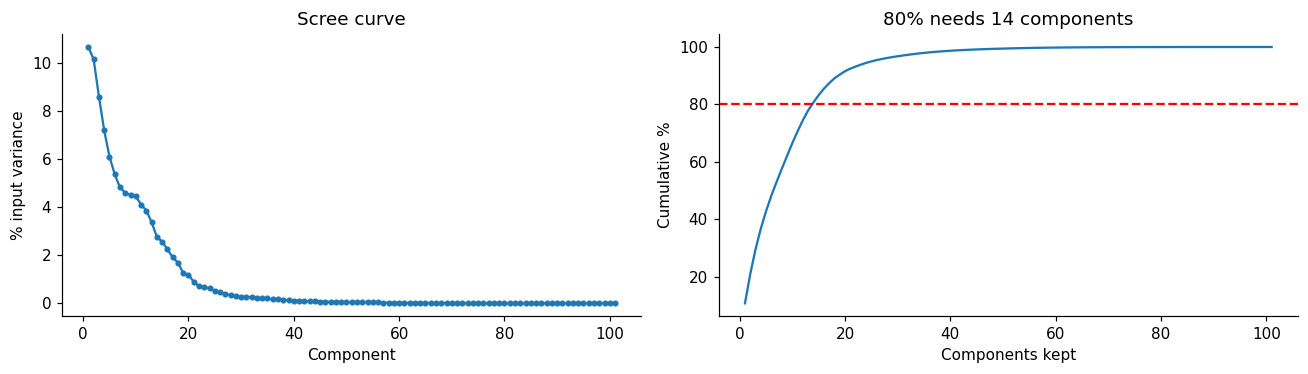

PC1 largest absolute loadings


,PC1
number__postFIRMConstructionIndicator,0.517
number__building_age,-0.476
number__log_deductible_usd,-0.304
number__log_totalContentsInsuranceCoverage,0.264
number__log_totalBuildingInsuranceCoverage,0.241
number__elevatedBuildingIndicator,0.222


PC2 largest absolute loadings


,PC2
number__log_numberOfUnits,0.490
number__log_policyCount,0.460
number__log_totalBuildingInsuranceCoverage,0.371
number__primaryResidenceIndicator,-0.322
number__log_totalContentsInsuranceCoverage,-0.275
number__log_deductible_usd,0.270


In [11]:
pca_explore=PCA(svd_solver='full').fit(Zfit)
cumulative=np.cumsum(pca_explore.explained_variance_ratio_)
k80=int(np.searchsorted(cumulative,.8)+1)
fig,ax=plt.subplots(1,2,figsize=(12,3.5))
ax[0].plot(np.arange(1,len(cumulative)+1),pca_explore.explained_variance_ratio_*100,marker='.')
ax[0].set(xlabel='Component',ylabel='% input variance',title='Scree curve')
ax[1].plot(np.arange(1,len(cumulative)+1),cumulative*100);ax[1].axhline(80,color='red',ls='--')
ax[1].set(xlabel='Components kept',ylabel='Cumulative %',title=f'80% needs {k80} components')
plt.tight_layout();plt.show()
loadings=pd.DataFrame(pca_explore.components_[:2].T,index=encoded_names,columns=['PC1','PC2'])
for pc in loadings:
    print(pc,'largest absolute loadings')
    display(loadings[pc].reindex(loadings[pc].abs().nlargest(6).index).to_frame())

### 5.2 Compare PCA, target-based selection and all columns
We compare the same boosting learner after keeping the top ten encoded columns or enough PCA components for 80% of input variation. Each pipeline learns its transformation from fitting data only. The supervised selector sees fitting outcomes, never validation outcomes.

In [12]:
reduced_results=try_candidates([('core','top 10 boosting'),('core','PCA boosting')])
reduction_compare=pd.DataFrame(rows).set_index('candidate').loc[['core | boosting','core | top 10 boosting','core | PCA boosting']]
display(reduction_compare[['R2','MAE $','median error $']].round(3))
best_reduction=reduction_compare.R2.idxmax()
display(Markdown(f'**Evidence:** among these three choices, **{best_reduction}** has the highest development R². '
                 'Keeping variation and keeping predictive information are different goals. We retain all three results in the final candidate table.'))

Finished core | top 10 boosting in 3.3 seconds


Finished core | PCA boosting in 3.5 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | PCA boosting,core,PCA boosting,0.064,"65,842.609","30,382.252"
core | top 10 boosting,core,top 10 boosting,0.058,"69,389.197","31,161.441"
core | small boosting,core,small boosting,0.042,"66,731.056","28,147.403"
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | boosting,core,boosting,0.038,"66,657.925","27,761.824"
core | forest,core,forest,0.034,"68,190.709","28,768.161"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core | tree depth 12,core,tree depth 12,0.020,"69,116.280","29,656.173"
core | flexible boosting,core,flexible boosting,0.018,"67,316.413","27,622.510"


,R2,MAE $,median error $
candidate,,,
core | boosting,0.038,"66,657.925","27,761.824"
core | top 10 boosting,0.058,"69,389.197","31,161.441"
core | PCA boosting,0.064,"65,842.609","30,382.252"


**Evidence:** among these three choices, **core | PCA boosting** has the highest development R². Keeping variation and keeping predictive information are different goals. We retain all three results in the final candidate table.

**Checkpoint · What the result changes**

With core boosting, validation R² changes from **0.038** to **0.058** using ten selected columns and **0.064** using PCA. This is the result for this preparation and period. We retain these candidates and next test information missing from the core table.

## 6. Return to the EDA: which source might fill the information gap?
### 6.1 Separate policy size from building and place
We compare policy-only, building/place-only and combined core features. The core result above is the reference. This checks whether a source adds information before we add weather.

In [13]:
source_results=try_candidates([('policy only','boosting'),('building + place','boosting')])

Finished policy only | boosting in 2.3 seconds


Finished building + place | boosting in 10.3 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | PCA boosting,core,PCA boosting,0.064,"65,842.609","30,382.252"
core | top 10 boosting,core,top 10 boosting,0.058,"69,389.197","31,161.441"
core | small boosting,core,small boosting,0.042,"66,731.056","28,147.403"
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | boosting,core,boosting,0.038,"66,657.925","27,761.824"
core | forest,core,forest,0.034,"68,190.709","28,768.161"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core | tree depth 12,core,tree depth 12,0.020,"69,116.280","29,656.173"
policy only | boosting,policy only,boosting,0.019,"71,712.040","32,730.330"


### 6.2 Add rain, then tracks, then both
EDA showed overlapping rain windows and storms with different local rain. A track can add broad hurricane exposure, but it does not measure the water depth at a house. We change the input group while keeping the learner fixed.

In [14]:
hazard_results=try_candidates([('core + rain','boosting'),('core + track','boosting'),
                               ('core + rain + track','boosting'),('compact hazards','boosting'),
                               ('core + track','flexible boosting')])

Finished core + rain | boosting in 12.8 seconds


Finished core + track | boosting in 12.0 seconds


Finished core + rain + track | boosting in 10.4 seconds


Finished compact hazards | boosting in 9.8 seconds


Finished core + track | flexible boosting in 27.2 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | PCA boosting,core,PCA boosting,0.064,"65,842.609","30,382.252"
core | top 10 boosting,core,top 10 boosting,0.058,"69,389.197","31,161.441"
core | small boosting,core,small boosting,0.042,"66,731.056","28,147.403"
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | boosting,core,boosting,0.038,"66,657.925","27,761.824"
core + track | boosting,core + track,boosting,0.036,"67,220.062","28,847.666"
core | forest,core,forest,0.034,"68,190.709","28,768.161"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core + track | flexible boosting,core + track,flexible boosting,0.033,"68,605.430","28,415.195"


**How to interpret a failure.** If added rain hurts, it may repeat existing information or identify familiar event patterns that do not transfer. If tracks help, that is evidence of added predictive value in this period, not proof that the model has measured storm surge. These are hypotheses to explain the pattern, not known causes of every error.

### 6.3 Add Census context without assuming income should improve prediction
Neighborhood housing context may relate to building values and coverage. It may also repeat policy information and describe areas only approximately. We test it rather than treating every join as an improvement.

In [15]:
census_results=try_candidates([('core + census','boosting'),('all sources','boosting')])

Finished core + census | boosting in 10.0 seconds


Finished all sources | boosting in 12.3 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core | PCA boosting,core,PCA boosting,0.064,"65,842.609","30,382.252"
core | top 10 boosting,core,top 10 boosting,0.058,"69,389.197","31,161.441"
core | small boosting,core,small boosting,0.042,"66,731.056","28,147.403"
core | tree depth 2,core,tree depth 2,0.039,"68,901.149","32,655.900"
core | boosting,core,boosting,0.038,"66,657.925","27,761.824"
core + track | boosting,core + track,boosting,0.036,"67,220.062","28,847.666"
core | forest,core,forest,0.034,"68,190.709","28,768.161"
core | dollar ridge,core,dollar ridge,0.033,"68,045.372","33,134.152"
core + track | flexible boosting,core + track,flexible boosting,0.033,"68,605.430","28,415.195"


### 6.4 Combine the sources: how many claims came from the same storm and place?
Rain, storm tracks and Census data added little so far. They describe the weather or the neighborhood, but not how badly one street was flooded. The claims file has one more clue that we have not used: **how many other claims came from the same neighborhood in the same storm**. Many claims close together usually means that water reached many homes.

We count claims only. We never use their payments or damage. Two points to remember:
- the counts are known only after the claims arrive, so this is a *retrospective* comparison, not a first-day forecast;
- we also add four simple ratios: condo building or not, coverage per unit, a storm-strength score (wind divided by distance), and wind on the right side of the storm.

We test the new inputs alone and together with the older sources. All models use the same boosting method and the same years.

In [16]:
mix_results=try_candidates([('core + local counts','boosting'),('core + claim counts','boosting'),('core + ratios','boosting'),
    ('core + track + ratios','boosting'),('core + track + claim counts','boosting'),('best mix','boosting'),('every source + mix','boosting')])

Finished core + local counts | boosting in 10.2 seconds


Finished core + claim counts | boosting in 11.1 seconds


Finished core + ratios | boosting in 11.2 seconds


Finished core + track + ratios | boosting in 12.2 seconds


Finished core + track + claim counts | boosting in 12.3 seconds


Finished best mix | boosting in 13.2 seconds


Finished every source + mix | boosting in 16.2 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
best mix | boosting,best mix,boosting,0.120,"60,828.923","29,142.263"
core + ratios | boosting,core + ratios,boosting,0.097,"61,403.911","27,418.640"
core + track + claim counts | boosting,core + track + claim counts,boosting,0.093,"62,236.122","29,523.146"
every source + mix | boosting,every source + mix,boosting,0.090,"61,493.584","28,463.466"
core + claim counts | boosting,core + claim counts,boosting,0.086,"61,919.192","28,257.994"
core + local counts | boosting,core + local counts,boosting,0.074,"62,561.423","27,920.035"
core + track + ratios | boosting,core + track + ratios,boosting,0.069,"63,990.476","28,533.284"
core | PCA boosting,core,PCA boosting,0.064,"65,842.609","30,382.252"
core | top 10 boosting,core,top 10 boosting,0.058,"69,389.197","31,161.441"


**Checkpoint · What the result changes**

Core boosting scores R² **0.038**. Adding claim counts for the same storm and place gives **0.086**. Adding storm tracks and ratios as well gives **0.120**. The claim counts help most. They tell the model how widely the storm flooded the area, which rain, tracks and Census values do not. Remember that the counts are known only after claims arrive.

## 7. Change the target scale: predict a share, then dollars
Direct tree models have difficulty extrapolating dollar payments to buildings much larger than the fitting examples. A payment share separates building size from the paid fraction.

We fit shares only where coverage is positive and limit fitting shares to 0–1. A predicted share is then multiplied by coverage. Claims paid above recorded coverage remain in evaluation, so this assumption can make errors. It is not a rule used to correct their recorded payment.

In [17]:
trace=d.loc[fit & d.totalBuildingInsuranceCoverage.gt(0),['amountPaidOnBuildingClaim','totalBuildingInsuranceCoverage']].sample(5,random_state=SEED)
trace['share before cap']=trace.amountPaidOnBuildingClaim/trace.totalBuildingInsuranceCoverage
trace['share used for fitting']=trace['share before cap'].clip(0,1)
display(trace.round(3))
print('Prediction example: a fitted share of 0.30 × $250,000 coverage = $75,000.')

,amountPaidOnBuildingClaim,totalBuildingInsuranceCoverage,share before cap,share used for fitting
183762,"15,591.130","250,000.000",0.062,0.062
74120,"47,463.030","83,000.000",0.572,0.572
39249,"64,877.360","125,000.000",0.519,0.519
8798,"3,907.320","250,000.000",0.016,0.016
252697,"18,845.090","45,000.000",0.419,0.419


Prediction example: a fitted share of 0.30 × $250,000 coverage = $75,000.


### 7.1 Keep the source comparisons under the new target design
We test core, core + track, core + rain + track, and all sources with the same coverage-share method. If this helps, we still need the storm checks; a better combined-year score need not mean every hurricane improves.

In [18]:
share_results=try_candidates([(name,'coverage fraction') for name in ['core','core + track','core + rain + track','all sources']])

Finished core | coverage fraction in 18.4 seconds


Finished core + track | coverage fraction in 17.8 seconds


Finished core + rain + track | coverage fraction in 17.5 seconds


Finished all sources | coverage fraction in 21.1 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
core + track | coverage fraction,core + track,coverage fraction,0.123,"67,010.848","29,550.293"
best mix | boosting,best mix,boosting,0.120,"60,828.923","29,142.263"
core + rain + track | coverage fraction,core + rain + track,coverage fraction,0.110,"68,282.084","28,490.932"
core | coverage fraction,core,coverage fraction,0.100,"66,872.081","28,014.271"
all sources | coverage fraction,all sources,coverage fraction,0.099,"68,725.609","28,313.343"
core + ratios | boosting,core + ratios,boosting,0.097,"61,403.911","27,418.640"
core + track + claim counts | boosting,core + track + claim counts,boosting,0.093,"62,236.122","29,523.146"
every source + mix | boosting,every source + mix,boosting,0.090,"61,493.584","28,463.466"
core + claim counts | boosting,core + claim counts,boosting,0.086,"61,919.192","28,257.994"


### 7.2 Share target with the combined inputs
We now give the best input sets from section 6.4 to the share model as well. This tells us whether the new claim-count information helps more under the share design or the dollar design.

In [19]:
share_mix_results=try_candidates([(name,'coverage fraction') for name in
    ['core + claim counts','core + track + claim counts','best mix','every source + mix']])

Finished core + claim counts | coverage fraction in 19.2 seconds


Finished core + track + claim counts | coverage fraction in 21.0 seconds


Finished best mix | coverage fraction in 21.0 seconds


Finished every source + mix | coverage fraction in 22.0 seconds


,features,family,R2,MAE $,median error $
candidate,,,,,
best mix | coverage fraction,best mix,coverage fraction,0.239,"60,824.346","28,995.884"
core + track + claim counts | coverage fraction,core + track + claim counts,coverage fraction,0.222,"61,360.556","28,888.096"
every source + mix | coverage fraction,every source + mix,coverage fraction,0.207,"61,338.641","28,786.158"
core + claim counts | coverage fraction,core + claim counts,coverage fraction,0.194,"61,666.516","28,052.063"
core + track | coverage fraction,core + track,coverage fraction,0.123,"67,010.848","29,550.293"
best mix | boosting,best mix,boosting,0.120,"60,828.923","29,142.263"
core + rain + track | coverage fraction,core + rain + track,coverage fraction,0.110,"68,282.084","28,490.932"
core | coverage fraction,core,coverage fraction,0.100,"66,872.081","28,014.271"
all sources | coverage fraction,all sources,coverage fraction,0.099,"68,725.609","28,313.343"


### Before choosing a winner: are the score gaps convincing?

We keep claims from the same named event together. Unnamed claims form one block per year. The block table shows how few independent event groups are available. In 1,000 bootstrap draws, we sample whole blocks with replacement and give every candidate the same draw. The 2.5% and 97.5% limits describe the middle 95% of these resampled scores. For a paired difference, a band crossing zero means the apparent gain is not clear under this check.

We also remove each evaluation block once, keeping the fitted predictions fixed. This tests whether one event changes the conclusion; it is different from the later section that refits after excluding a storm.

**Limits:** these are descriptive event-bootstrap bands, not proof of significance or a reliable interval for every future storm. There are few events, and claims can also be related across events. The models are not refitted in the bootstrap, so fitting uncertainty is excluded. The bands are not adjusted for the many candidates or cutoff choices. The highest validation score can be partly luck. We keep the original winner as a working choice, without claiming it is clearly better. A new, untouched storm period or nested event-level model selection would be needed for stronger evidence.

In [20]:
from model_audit import event_labels, event_score_audit
uncertainty, paired_gaps, omitted_gaps, event_blocks = event_score_audit(
    ydev[valid], validation_predictions, event_labels(d.loc[valid]),
    metric='R2', pairs=[('core | PCA boosting', 'core | boosting'), ('core | top 10 boosting', 'core | boosting'), ('core | coverage fraction', 'core | boosting'), ('core + track | coverage fraction', 'core | coverage fraction'), ('core + claim counts | boosting', 'core | boosting'), ('best mix | coverage fraction', 'core + track | coverage fraction')], repeats=1000, seed=SEED)
display(event_blocks)
print('Validation event blocks:', len(event_blocks), '; candidates:', len(validation_predictions))
display(uncertainty.sort_values('R2',ascending=False).round(3))
display(paired_gaps.round(3))
save_table(event_blocks,'02_validation_event_blocks')
save_table(uncertainty,'02_validation_uncertainty')
save_table(paired_gaps,'02_validation_paired_gaps')
save_table(omitted_gaps,'02_validation_omit_event_gaps')
for label,row in paired_gaps.iterrows():
    reading='crosses zero; no clear gain under this check' if row['paired 2.5%']<=0<=row['paired 97.5%'] else 'does not cross zero, but selection and few-event limits remain'
    display(Markdown(f"**{label}:** difference {row['difference']:+.3f}, paired band [{row['paired 2.5%']:+.3f}, {row['paired 97.5%']:+.3f}]; {reading}."))

,claims
event,
Hurricane Ian,37105
Hurricane Idalia,4775
unnamed-2022,4557
unnamed-2023,3735
April Florida Flooding,3002
December Nor'easter,1556
California Atmospheric River,1324
Late-September New York Flooding,1303
Hurricane Nicole,1172


Validation event blocks: 26 ; candidates: 35


,R2,event bootstrap 2.5%,event bootstrap 97.5%,omit-event minimum,omit-event maximum,valid bootstrap draws
candidate,,,,,,
best mix | coverage fraction,0.239,-0.778,0.255,-0.343,0.250,1000
core + track + claim counts | coverage fraction,0.222,-0.891,0.240,-0.385,0.235,1000
every source + mix | coverage fraction,0.207,-0.932,0.226,-0.424,0.221,1000
core + claim counts | coverage fraction,0.194,-0.539,0.208,-0.213,0.203,1000
core + track | coverage fraction,0.123,-0.451,0.134,-0.207,0.129,1000
best mix | boosting,0.120,0.096,0.337,0.114,0.306,1000
core + rain + track | coverage fraction,0.110,-0.707,0.124,-0.364,0.120,1000
core | coverage fraction,0.100,-0.572,0.115,-0.215,0.106,1000
all sources | coverage fraction,0.099,-0.759,0.113,-0.425,0.108,1000


,difference,paired 2.5%,paired 97.5%,omit-event minimum,omit-event maximum
comparison,,,,,
core | PCA boosting minus core | boosting,0.026,-0.060,0.028,-0.021,0.026
core | top 10 boosting minus core | boosting,0.020,-0.100,0.023,-0.066,0.022
core | coverage fraction minus core | boosting,0.062,-0.807,0.085,-0.492,0.070
core + track | coverage fraction minus core | coverage fraction,0.023,-0.089,0.142,0.008,0.025
core + claim counts | boosting minus core | boosting,0.048,0.012,0.057,0.037,0.049
best mix | coverage fraction minus core + track | coverage fraction,0.116,-0.375,0.129,-0.136,0.122


**core | PCA boosting minus core | boosting:** difference +0.026, paired band [-0.060, +0.028]; crosses zero; no clear gain under this check.

**core | top 10 boosting minus core | boosting:** difference +0.020, paired band [-0.100, +0.023]; crosses zero; no clear gain under this check.

**core | coverage fraction minus core | boosting:** difference +0.062, paired band [-0.807, +0.085]; crosses zero; no clear gain under this check.

**core + track | coverage fraction minus core | coverage fraction:** difference +0.023, paired band [-0.089, +0.142]; crosses zero; no clear gain under this check.

**core + claim counts | boosting minus core | boosting:** difference +0.048, paired band [+0.012, +0.057]; does not cross zero, but selection and few-event limits remain.

**best mix | coverage fraction minus core + track | coverage fraction:** difference +0.116, paired band [-0.375, +0.129]; crosses zero; no clear gain under this check.

**Checkpoint · What the result changes**

Core coverage-share prediction gives R² **0.100**. Adding tracks under that design gives **0.123**. These are point estimates. Read the paired event audit before calling either change a clear gain. The frozen working choice must now face later-year evaluation.

**Checkpoint · What the result changes**

PCA versus core boosting has a point difference of **+0.026**, with a paired event-bootstrap band **[-0.060, +0.028]**. There are **26 evaluation blocks**, many small, and the largest contains **60.8%** of validation claims. The band crosses zero, so this check does not show a clear gain. Removing **Hurricane Ian** changes the gap to **-0.021**. We keep the original highest-scoring model as a working choice. These fixed-model bands do not correct for searching many candidates or prove performance on a new storm.

## 8. Freeze the development choice
We have now seen why each candidate was tested. We select the highest validation R² among the declared candidates and keep weak rows visible. We do not choose another model after reading later-year outcomes.

The ranking selects a working model, not a statistically established winner. Read the paired bands and event-deletion results before describing any small gap as an improvement.

,features,family,R2,MAE $,median error $
candidate,,,,,
best mix | coverage fraction,best mix,coverage fraction,0.239,"60,824.346","28,995.884"
core + track + claim counts | coverage fraction,core + track + claim counts,coverage fraction,0.222,"61,360.556","28,888.096"
every source + mix | coverage fraction,every source + mix,coverage fraction,0.207,"61,338.641","28,786.158"
core + claim counts | coverage fraction,core + claim counts,coverage fraction,0.194,"61,666.516","28,052.063"
core + track | coverage fraction,core + track,coverage fraction,0.123,"67,010.848","29,550.293"
best mix | boosting,best mix,boosting,0.120,"60,828.923","29,142.263"
core + rain + track | coverage fraction,core + rain + track,coverage fraction,0.110,"68,282.084","28,490.932"
core | coverage fraction,core,coverage fraction,0.100,"66,872.081","28,014.271"
all sources | coverage fraction,all sources,coverage fraction,0.099,"68,725.609","28,313.343"


Choice frozen from validation: best mix | coverage fraction


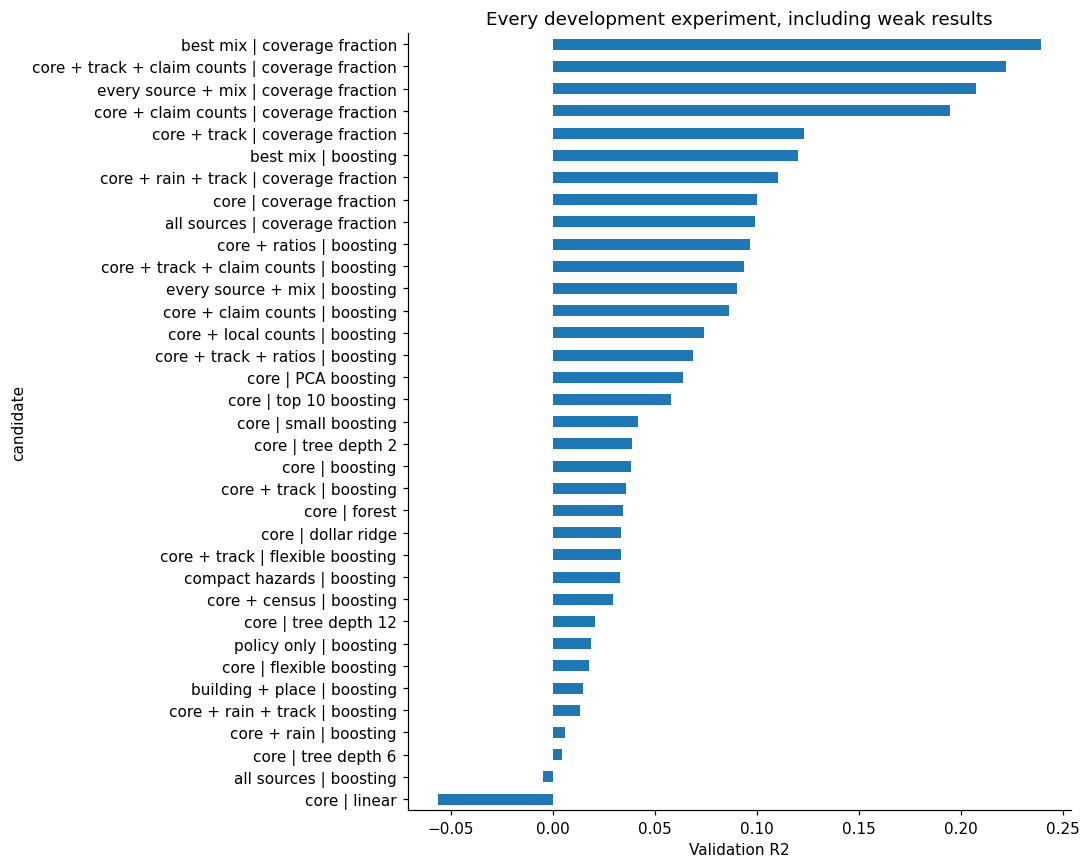

In [21]:
comparison=pd.DataFrame(rows).set_index('candidate').sort_values('R2',ascending=False)
metric='R2'
selected=comparison.index[0]
selected_features=comparison.loc[selected,'features'];selected_family=comparison.loc[selected,'family']
selected_cols=FEATURE_SETS[selected_features]
display(comparison.round(3));print('Choice frozen from validation:',selected)
save_table(comparison,'02_validation')
comparison.R2.sort_values().plot.barh(figsize=(10,8),title='Every development experiment, including weak results')
plt.xlabel('Validation R2');plt.tight_layout();plt.show()

## 9. Evaluate later years once the choice is frozen
We now refit the selected candidate on 2020–2023. We also evaluate a pre-defined core-only boosting model and a simple baseline. These show the extra value of the selected approach. We do not choose another model after reading these results.

The same claims are used for each comparison. Missing external values are handled by the training pipeline. The external measurements remain retrospective inputs.

In [22]:
selected_model=candidate_model(d[selected_cols],task,selected_family)
ix=d.index[train]
if selected_family=='forest' and len(ix)>80000:
    ix=d.loc[ix].sample(80000,random_state=SEED).index
selected_model.fit(d.loc[ix,selected_cols],y.loc[ix])
core_model=candidate_model(d[CORE],task,'boosting').fit(d.loc[train,CORE],y[train])
predictions={}
if task=='regression':
    predictions['mean baseline']=np.full(test.sum(),y[train].mean())
    predictions['median baseline']=np.full(test.sum(),y[train].median())
    predictions['core boosting']=np.maximum(core_model.predict(d.loc[test,CORE]),0)
    predictions['selected on earlier years']=np.maximum(selected_model.predict(d.loc[test,selected_cols]),0)
    final=pd.DataFrame({k:regression_scores(y[test],p) for k,p in predictions.items()}).T
else:
    predictions['constant training share']=np.full(test.sum(),y[train].mean())
    predictions['core boosting']=core_model.predict_proba(d.loc[test,CORE])[:,1]
    predictions['selected on earlier years']=selected_model.predict_proba(d.loc[test,selected_cols])[:,1]
    final=pd.DataFrame({k:classification_scores(y[test],p,threshold if k=='selected on earlier years' else .5)
                        for k,p in predictions.items()}).T
    final.loc['selected at threshold 0.50']=classification_scores(y[test],predictions['selected on earlier years'],.5)
display(final.round(3))
save_table(final,'02_later_years' if task=='regression' else '03_later_years')
p=predictions['selected on earlier years']

,R2,MAE $,median error $
mean baseline,-0.024,"68,727.689","52,836.201"
median baseline,-0.175,"72,973.964","32,288.520"
core boosting,0.027,"54,971.700","29,865.982"
selected on earlier years,0.136,"54,088.805","27,997.549"


### 9.0 Separate target design from hurricane-track information
The development table already includes core-only coverage-share prediction. The earlier later-year table did not, so the combined gain could not be separated. We now complete a two-by-two comparison: dollar or coverage-share prediction, each with core inputs or core plus tracks. All four fit 2020–2023 and score the same later-year claims.

This is an **additional audit after viewing test results**, not a new independent test. We keep the original selected model. The original share model uses 220 boosting rounds rather than 140. We therefore add two **matched dollar** rows using the same 220 rounds and the same positive-coverage fitting claims as the share models. Compare each share model with its matched dollar row to isolate the target design more carefully. The original four rows remain visible, and track comparisons within each design keep settings fixed.

In [23]:
ablation_predictions={'core dollar':predictions['core boosting']}
for label,features,family in [('core share','core','coverage fraction'),
                              ('core + track share','core + track','coverage fraction'),
                              ('core + track dollar','core + track','boosting')]:
    cols=FEATURE_SETS[features]
    fitted=candidate_model(d[cols],task,family).fit(d.loc[train,cols],y[train])
    ablation_predictions[label]=np.asarray(np.maximum(fitted.predict(d.loc[test,cols]),0))
# Match the share model's 220 rounds and positive-coverage fitting rows.
matched_fit=train & d.totalBuildingInsuranceCoverage.gt(0)
for label,features in [('core dollar matched','core'),('core + track dollar matched','core + track')]:
    cols=FEATURE_SETS[features]
    fitted=model_for(d[cols],task,iterations=220,leaves=15,l2=10).fit(d.loc[matched_fit,cols],y[matched_fit])
    ablation_predictions[label]=np.asarray(np.maximum(fitted.predict(d.loc[test,cols]),0))
# The model frozen on the 2022-2023 validation years, and the same inputs with the other target design.
ablation_predictions['selected model']=np.asarray(predictions['selected on earlier years'])
if selected_family=='coverage fraction':
    other_label='selected inputs, dollar matched'
    fitted=model_for(d[selected_cols],task,iterations=220,leaves=15,l2=10).fit(d.loc[matched_fit,selected_cols],y[matched_fit])
else:
    other_label='selected inputs, share target'
    fitted=candidate_model(d[selected_cols],task,'coverage fraction').fit(d.loc[train,selected_cols],y[train])
ablation_predictions[other_label]=np.asarray(np.maximum(fitted.predict(d.loc[test,selected_cols]),0))
ablation=pd.DataFrame({label:regression_scores(y[test],pred) for label,pred in ablation_predictions.items()}).T
display(ablation.round(3));save_table(ablation,'02_later_target_track_ablation')
later_uncertainty,later_gaps,later_omitted,later_blocks=event_score_audit(
    y[test],ablation_predictions,event_labels(d.loc[test]),metric='R2',
    pairs=[('core share','core dollar'),('core + track share','core share'),
           ('core + track dollar','core dollar'),
           ('core share','core dollar matched'),
           ('core + track share','core + track dollar matched'),
           ('selected model','core + track dollar'),
           ('selected model',other_label)],repeats=1000,seed=SEED)
display(later_blocks);display(later_uncertainty.round(3));display(later_gaps.round(3))
save_table(later_uncertainty,'02_later_ablation_uncertainty')
save_table(later_gaps,'02_later_ablation_paired_gaps')
save_table(later_omitted,'02_later_ablation_omit_event_gaps')
save_table(later_blocks,'02_later_event_blocks')

,R2,MAE $,median error $
core dollar,0.027,"54,971.700","29,865.982"
core share,-0.006,"57,787.239","29,997.262"
core + track share,0.273,"53,394.490","28,280.312"
core + track dollar,0.415,"51,962.167","29,389.224"
core dollar matched,0.026,"54,702.058","29,696.757"
core + track dollar matched,0.402,"51,857.105","29,182.323"
selected model,0.136,"54,088.805","27,997.549"
"selected inputs, dollar matched",-0.796,"55,389.383","28,347.302"


,claims
event,
Hurricane Helene,50440
Hurricane Milton,16253
unnamed-2024,7460
unnamed-2025,4922
Hurricane Debby,1909
Central U.S. April Flooding,1830
Hurricane Francine,1744
Hurricane Beryl,1522
June South Florida Flooding,1158


,R2,event bootstrap 2.5%,event bootstrap 97.5%,omit-event minimum,omit-event maximum,valid bootstrap draws
candidate,,,,,,
core dollar,0.027,-0.600,0.188,-0.346,0.091,1000
core share,-0.006,-1.719,0.186,-1.281,0.133,1000
core + track share,0.273,-0.511,0.343,-0.257,0.317,1000
core + track dollar,0.415,0.194,0.432,0.233,0.428,1000
core dollar matched,0.026,-0.489,0.183,-0.274,0.078,1000
core + track dollar matched,0.402,0.195,0.418,0.232,0.414,1000
selected model,0.136,-0.516,0.212,-0.361,0.196,1000
"selected inputs, dollar matched",-0.796,-1.003,0.255,-0.881,0.185,1000


,difference,paired 2.5%,paired 97.5%,omit-event minimum,omit-event maximum
comparison,,,,,
core share minus core dollar,-0.033,-1.529,0.111,-0.934,0.042
core + track share minus core share,0.279,0.153,1.294,0.183,1.024
core + track dollar minus core dollar,0.388,0.038,0.820,0.337,0.580
core share minus core dollar matched,-0.032,-1.546,0.124,-1.007,0.055
core + track share minus core + track dollar matched,-0.129,-0.745,-0.070,-0.489,-0.097
selected model minus core + track dollar,-0.279,-0.756,-0.086,-0.594,-0.232
"selected model minus selected inputs, dollar matched",0.932,-0.687,1.191,-0.545,1.077


### 9.0a How much do condos affect the score?
We keep every genuine large claim. Below we score **every ablation model** on condos and other buildings separately, then on all claims. We show the share of total squared error from each group and the ten largest selected-model errors. Squared error gives a very large mistake much more weight than a typical mistake.

Removing condos changes the population, so its R² is not directly comparable with the full-population R²: the variation in observed payments also changes. The error shares show concentration; they do not prove that condos alone cause the model's performance.

The final table uses the same total payment variation for every group. Its contributions add up to the overall R² change from core dollar prediction. This lets us see which group accounts for a gain without adding subgroup R² values.

In [24]:
audit=d.loc[test].copy()
audit['size group']=np.where(audit.occupancy.eq('15'),'condo building','other building')
subgroup_rows=[]
for label,pred in ablation_predictions.items():
    squared=(y[test].to_numpy()-np.asarray(pred))**2
    for group in ['all claims','condo building','other building']:
        mask=np.ones(len(audit),dtype=bool) if group=='all claims' else audit['size group'].eq(group).to_numpy()
        subgroup_rows.append({'model':label,'group':group,'claims':mask.sum(),
            'share of model squared error':squared[mask].sum()/squared.sum(),
            **regression_scores(y[test].to_numpy()[mask],np.asarray(pred)[mask])})
subgroup_audit=pd.DataFrame(subgroup_rows).set_index(['model','group'])
display(subgroup_audit.round(3));save_table(subgroup_audit,'02_later_condo_ablation')
selected_squared=(y[test].to_numpy()-np.asarray(p))**2
top_ten=np.argsort(selected_squared)[-10:]
print(f'Top ten errors: {audit.iloc[top_ten].occupancy.eq("15").sum()} condos; '
      f'{selected_squared[top_ten].sum()/selected_squared.sum():.1%} of selected-model squared error.')
# Decompose the overall R2 change using one common denominator.
observed=y[test].to_numpy()
global_variation=np.sum((observed-observed.mean())**2)
reference_squared=(observed-np.asarray(ablation_predictions['core dollar']))**2
contributions=[]
for label,pred in ablation_predictions.items():
    improvement=reference_squared-(observed-np.asarray(pred))**2
    for group in ['condo building','other building']:
        mask=audit['size group'].eq(group).to_numpy()
        contributions.append({'model':label,'group':group,
            'contribution to overall R2 gain vs core dollar':improvement[mask].sum()/global_variation,
            'share of overall payment variation':np.sum((observed[mask]-observed.mean())**2)/global_variation})
contribution_table=pd.DataFrame(contributions).set_index(['model','group'])
display(contribution_table.round(4));save_table(contribution_table,'02_later_R2_contributions')


claims  \
model                           group                    
core dollar                     all claims       93194   
                                condo building    7486   
                                other building   85708   
core share                      all claims       93194   
                                condo building    7486   
                                other building   85708   
core + track share              all claims       93194   
                                condo building    7486   
                                other building   85708   
core + track dollar             all claims       93194   
                                condo building    7486   
                                other building   85708   
core dollar matched             all claims       93194   
                                condo building    7486   
                                other building   85708   
core + track dollar matched     all claims       93194   
                                condo building    7486   
                                other building   85708   
selected model                  all claims       93194   
                                condo building    7486   
                                other building   85708   
selected inputs, dollar matched all claims       93194   
                                condo building    7486   
                                other building   85708   

                                                share of model squared error  \
model                           group                                          
core dollar                     all claims                             1.000   
                                condo building                         0.820   
                                other building                         0.180   
core share                      all claims                             1.000   
                                condo building                         0.825   
                                other building                         0.175   
core + track share              all claims                             1.000   
                                condo building                         0.752   
                                other building                         0.248   
core + track dollar             all claims                             1.000   
                                condo building                         0.673   
                                other building                         0.327   
core dollar matched             all claims                             1.000   
                                condo building                         0.822   
                                other building                         0.178   
core + track dollar matched     all claims                             1.000   
                                condo building                         0.673   
                                other building                         0.327   
selected model                  all claims                             1.000   
                                condo building                         0.807   
                                other building                         0.193   
selected inputs, dollar matched all claims                             1.000   
                                condo building                         0.909   
                                other building                         0.091   

                                                   R2       MAE $  \
model                           group                               
core dollar                     all claims      0.027  54,971.700   
                                condo building -0.196 196,189.176   
                                other building  0.371  42,637.332   
core share                      all claims     -0.006  57,787.239   
                                condo buildi

Top ten errors: 10 condos; 13.6% of selected-model squared error.


contribution to overall R2 gain vs core dollar  \
model                           group                                                            
core dollar                     condo building                                           0.000   
                                other building                                           0.000   
core share                      condo building                                          -0.032   
                                other building                                          -0.001   
core + track share              condo building                                           0.252   
                                other building                                          -0.006   
core + track dollar             condo building                                           0.404   
                                other building                                          -0.016   
core dollar matched             condo building                                          -0.003   
                                other building                                           0.001   
core + track dollar matched     condo building                                           0.396   
                                other building                                          -0.021   
selected model                  condo building                                           0.101   
                                other building                                           0.008   
selected inputs, dollar matched condo building                                          -0.835   
                                other building                                           0.012   

                                                share of overall payment variation  
model                           group                                               
core dollar                     condo building                               0.718  
                                other building                               0.282  
core share                      condo building                               0.718  
                                other building                               0.282  
core + track share              condo building                               0.718  
                                other building                               0.282  
core + track dollar             condo building                               0.718  
                                other building                               0.282  
core dollar matched             condo building                               0.718  
                                other building                               0.282  
core + track dollar matched     condo building                               0.718  
                                other building                               0.282  
selected model                  condo building                               0.718  
                                other building                               0.282  
selected inputs, dollar matched condo building                               0.718  
                                other building                               0.282

### 9.0b Do the claim counts help on the later years?
The claim counts raised the 2022–2023 validation scores a lot, so the model chosen on those years uses them. We now check them on 2024–2025, separately for condos and other buildings. The check is again made after seeing the test years, so it explains the result and does not choose a new model.

We also try a *two-part* model as an exploration: other buildings use the claim counts, and condos use the track and ratio inputs without them. Condo claims are huge, and the counts of a very large storm can be far outside the range seen in training.

In [25]:
sets_to_check={'core + track':'core + track','core + track + ratios':'core + track + ratios',
               'core + track + claim counts':'core + track + claim counts','best mix':'best mix'}
check_rows=[];check_pred={}
condo_mask=(d.loc[test,'occupancy']=='15').to_numpy();observed=y[test].to_numpy()
for label,features in sets_to_check.items():
    cols=FEATURE_SETS[features]
    for family in ['boosting','coverage fraction']:
        fitted=candidate_model(d[cols],task,family).fit(d.loc[train,cols],y[train])
        pred=np.asarray(np.maximum(fitted.predict(d.loc[test,cols]),0));check_pred[(label,family)]=pred
        check_rows.append({'inputs':label,'target':family,'all claims R2':r2_score(observed,pred),
                           'condo R2':r2_score(observed[condo_mask],pred[condo_mask]),
                           'other buildings R2':r2_score(observed[~condo_mask],pred[~condo_mask])})
two_part=np.where(condo_mask,check_pred[('core + track + ratios','boosting')],check_pred[('core + track + claim counts','coverage fraction')])
check_rows.append({'inputs':'two-part: condos without counts, others with counts','target':'mixed','all claims R2':r2_score(observed,two_part),
                   'condo R2':r2_score(observed[condo_mask],two_part[condo_mask]),'other buildings R2':r2_score(observed[~condo_mask],two_part[~condo_mask])})
claim_count_check=pd.DataFrame(check_rows).set_index(['inputs','target'])
display(claim_count_check.round(3));save_table(claim_count_check,'02_later_claim_count_check')

all claims R2  \
inputs                                             target                             
core + track                                       boosting                   0.415   
                                                   coverage fraction          0.273   
core + track + ratios                              boosting                   0.437   
                                                   coverage fraction          0.226   
core + track + claim counts                        boosting                  -0.909   
                                                   coverage fraction          0.015   
best mix                                           boosting                  -0.740   
                                                   coverage fraction          0.136   
two-part: condos without counts, others with co... mixed                      0.456   

                                                                      condo R2  \
inputs                                             target                        
core + track                                       boosting              0.410   
                                                   coverage fraction     0.182   
core + track + ratios                              boosting              0.429   
                                                   coverage fraction     0.115   
core + track + claim counts                        boosting             -1.609   
                                                   coverage fraction    -0.232   
best mix                                           boosting             -1.361   
                                                   coverage fraction    -0.045   
two-part: condos without counts, others with co... mixed                 0.429   

                                                                      other buildings R2  
inputs                                             target                                 
core + track                                       boosting                        0.313  
                                                   coverage fraction               0.351  
core + track + ratios                              boosting                        0.346  
                                                   coverage fraction               0.343  
core + track + claim counts                        boosting                        0.399  
                                                   coverage fraction               0.414  
best mix                                           boosting                        0.410  
                                                   coverage fraction               0.401  
two-part: condos without counts, others with co... mixed                           0.414

In [26]:
other_gain=(claim_count_check.loc[('core + track + claim counts','coverage fraction'),'other buildings R2']
            -claim_count_check.loc[('core + track','coverage fraction'),'other buildings R2'])
condo_change=(claim_count_check.loc[('core + track + claim counts','boosting'),'condo R2']
              -claim_count_check.loc[('core + track','boosting'),'condo R2'])
display(Markdown(
    f"**Reading the table.** For ordinary buildings, adding claim counts changes R² by **{other_gain:+.3f}** under the share target, so the counts carry real information. "
    f"For condos under the dollar target the change is **{condo_change:+.3f}**: the counts can push a condo prediction far from the truth, and a few such claims ruin the overall score. "
    "This is why the model chosen on 2022–2023 scores lower on the later years than a plain track model. "
    "It is an honest warning: a gain on validation years does not always carry over, and condos need their own care."))

**Reading the table.** For ordinary buildings, adding claim counts changes R² by **+0.064** under the share target, so the counts carry real information. For condos under the dollar target the change is **-2.019**: the counts can push a condo prediction far from the truth, and a few such claims ruin the overall score. This is why the model chosen on 2022–2023 scores lower on the later years than a plain track model. It is an honest warning: a gain on validation years does not always carry over, and condos need their own care.

**Checkpoint · What the result changes**

Later-year R² is **0.027** for core dollar prediction, **-0.006** for core share prediction, and **0.273** for share prediction with tracks. The track addition within the share design has a difference of **+0.279**, with paired band **[+0.153, +1.294]**. R² can be negative, so a difference or its band can exceed one. The matched dollar rows give R² **0.026** with core inputs and **0.402** with tracks. These rows match the share models in boosting settings and fitting population. With tracks, share minus matched-dollar R² is **-0.129**, with band **[-0.745, -0.070]**. This check supports the dollar target over the share target in these later years.

For the selected model, condos make up **8.0%** of claims and **80.7%** of squared error. Its R² is **-0.045** within condos and **0.401** within other buildings. These subgroup R² values use different outcome variation; they are not additive. The audit describes the viewed test years and does not change the earlier development choice.

### 9.1 Inspect mistakes rather than reporting one score
The scatter plot compares recorded and predicted payment. We also inspect the ten largest errors and separate condo buildings from other buildings. R² and median error can disagree because they give different weight to large mistakes.

,claims,R2,MAE $,median error $
group,,,,
condo building,7486,-0.040,"204,408.730","83,358.600"
other building,85708,0.400,"40,959.400","26,050.990"


,floodEvent,occupancy_name,amountPaidOnBuildingClaim,prediction,totalBuildingInsuranceCoverage,policyCount,absolute_error
132938,Hurricane Helene,condo building,"375,716.000","9,543,888.000","78,560,000.000",366.000,"9,168,172.000"
103258,Hurricane Helene,condo building,"134,918.000","5,440,888.000","40,250,000.000",161.000,"5,305,970.000"
71588,Hurricane Helene,condo building,"28,626.000","4,720,778.000","67,000,000.000",268.000,"4,692,152.000"
99561,Hurricane Helene,condo building,"1,446,386.000","6,095,502.000","58,270,000.000",336.000,"4,649,116.000"
106244,Hurricane Helene,condo building,"613,309.000","5,108,827.000","37,500,000.000",150.000,"4,495,517.000"
172647,Hurricane Helene,condo building,"5,754,277.000","2,548,897.000","23,265,000.000",114.000,"3,205,380.000"
19671,Hurricane Helene,condo building,"5,441,446.000","2,378,618.000","25,500,000.000",102.000,"3,062,828.000"
232368,Hurricane Helene,condo building,"5,592,634.000","2,548,897.000","23,265,000.000",114.000,"3,043,737.000"
191515,Hurricane Helene,condo building,"4,247,992.000","1,230,190.000","10,520,000.000",54.000,"3,017,802.000"
75548,Hurricane Helene,condo building,"110,768.000","3,113,057.000","35,000,000.000",140.000,"3,002,288.000"


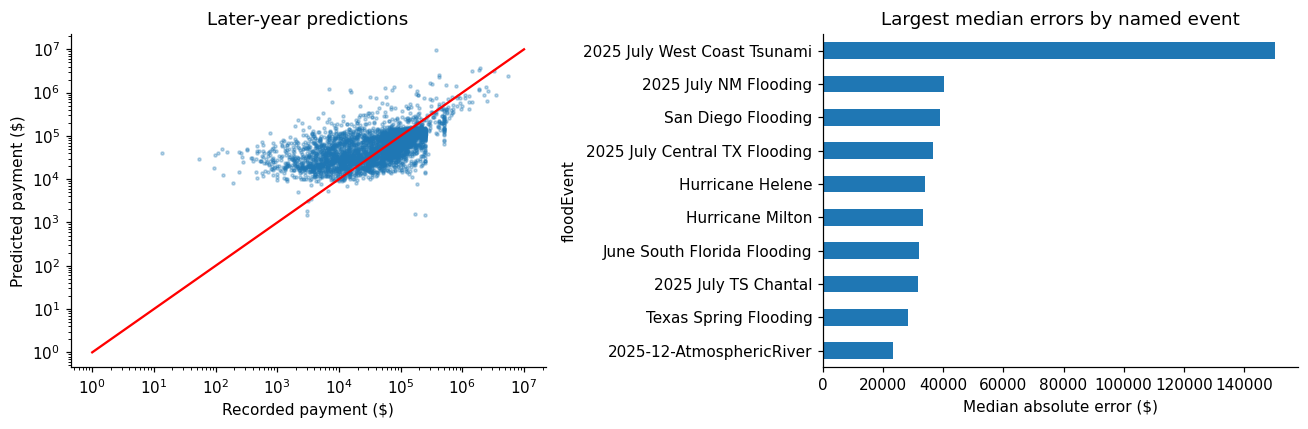

In [27]:
z=d[test].copy(); z['prediction']=p; z['absolute_error']=np.abs(y[test]-p)
z['size_group']=np.where(z.occupancy=='15','condo building','other building')
size_rows=[]
for label,g in z.groupby('size_group'):
    size_rows.append({'group':label,'claims':len(g),**regression_scores(g.amountPaidOnBuildingClaim,g.prediction)})
display(pd.DataFrame(size_rows).set_index('group').round(2))
errors=z.nlargest(10,'absolute_error')[['floodEvent','occupancy_name','amountPaidOnBuildingClaim','prediction',
                                       'totalBuildingInsuranceCoverage','policyCount','absolute_error']]
display(errors.round(0))
fig,ax=plt.subplots(1,2,figsize=(12,4))
s=z.sample(min(4000,len(z)),random_state=SEED)
ax[0].scatter(s.amountPaidOnBuildingClaim,s.prediction,s=4,alpha=.3)
ax[0].plot([1,1e7],[1,1e7],color='red');ax[0].set(xscale='log',yscale='log',xlabel='Recorded payment ($)',ylabel='Predicted payment ($)',title='Later-year predictions')
z.groupby('floodEvent').absolute_error.median().sort_values().tail(10).plot.barh(ax=ax[1],title='Largest median errors by named event')
ax[1].set_xlabel('Median absolute error ($)');plt.tight_layout();plt.show()

## 10. Does the improvement hold across excluded storms?
We refit the frozen model while leaving out each of the six largest named events. This checks sensitivity to event identity. It is **not** a historical forecast: training can include storms that occurred after the excluded storm. The feature choice was already informed by some development storms, so this is a sensitivity check rather than an independent model-selection test.

We report R² and dollar errors for each event. A simple average across storms gives every storm equal weight; it differs from a score across all claims.

In [28]:
storm_rows=[]
for event in d.floodEvent.value_counts().head(6).index:
    held=d.floodEvent.eq(event); other=~held
    yy=y.copy() if task=='regression' else (d.buildingDamageAmount>=d.loc[other,'buildingDamageAmount'].quantile(.8)).astype(int)
    ix=d.index[other]
    if selected_family=='forest' and len(ix)>80000: ix=d.loc[ix].sample(80000,random_state=SEED).index
    model=candidate_model(d[selected_cols],task,selected_family).fit(d.loc[ix,selected_cols],yy.loc[ix])
    pp=model.predict(d.loc[held,selected_cols]) if task=='regression' else model.predict_proba(d.loc[held,selected_cols])[:,1]
    sc=regression_scores(yy[held],np.maximum(pp,0)) if task=='regression' else classification_scores(yy[held],pp,threshold)
    storm_rows.append({'storm':event,'claims':held.sum(),**sc})
storm_table=pd.DataFrame(storm_rows).set_index('storm')
display(storm_table.round(3))
save_table(storm_table,'02_storm_sensitivity' if task=='regression' else '03_storm_sensitivity')

,claims,R2,MAE $,median error $
storm,,,,
Hurricane Helene,50440,0.242,"61,211.678","32,239.872"
Hurricane Ian,37105,0.320,"72,645.930","38,910.064"
Hurricane Ida,21652,0.103,"34,847.301","19,977.502"
Hurricane Milton,16253,-0.363,"53,469.429","31,453.451"
Hurricane Sally,6124,-2.201,"40,426.458","20,546.238"
Hurricane Idalia,4775,0.365,"33,820.129","22,130.810"


### 10.1 Why does the score stay modest? Three simple tests
The scores above are lower than we would like. Before we write the final answer, we test three common explanations. Each test is easy to read: we change one thing and look at the later-year score.

1. **Do we need more data?** We train on a quarter, a half and all of the 2020–2023 claims.
2. **Is the missing piece a better model or better information?** We add one field that an early model could not know: the inspector's damage estimate. This is only a thought experiment. It shows how much a missing fact can matter.
3. **Is the problem the same for every building?** We compare condo buildings with all other buildings.

In [29]:
rng_curve=np.random.default_rng(SEED)
train_ids=np.flatnonzero(train.to_numpy())
curve_rows=[]
for share in [.25,.5,1.0]:
    chosen_rows=np.sort(rng_curve.choice(train_ids,int(len(train_ids)*share),replace=False)) if share<1 else train_ids
    curve_model=candidate_model(d[selected_cols],task,selected_family)
    curve_model.fit(d.iloc[chosen_rows][selected_cols],y.iloc[chosen_rows])
    curve_pred=np.asarray(np.maximum(curve_model.predict(d.loc[test,selected_cols]),0))
    curve_rows.append({'training claims':len(chosen_rows),'later-year R2':r2_score(y[test],curve_pred)})
curve_table=pd.DataFrame(curve_rows).set_index('training claims')
display(curve_table.round(3))
save_table(curve_table,'02_learning_curve')

,later-year R2
training claims,
29943,-0.080
59886,0.071
119772,0.136


In [30]:
# Thought experiment only: the damage estimate is written after the flood, so a real early model cannot use it.
what_if=d.copy()
what_if['log_damage_estimate']=np.log1p(what_if.buildingDamageAmount.clip(lower=0))
what_if_cols=selected_cols+['log_damage_estimate']
what_if_model=candidate_model(what_if[what_if_cols],task,'boosting').fit(what_if.loc[train,what_if_cols],y[train])
what_if_pred=np.maximum(what_if_model.predict(what_if.loc[test,what_if_cols]),0)
information=pd.DataFrame({'later-year R2':{
    'selected inputs':r2_score(y[test],np.asarray(p)),
    'selected inputs + inspector damage estimate (not allowed)':r2_score(y[test],what_if_pred)}})
display(information.round(3))
save_table(information,'02_missing_information_test')
condo_test=(d.loc[test,'occupancy']=='15').to_numpy()
segment=pd.DataFrame({'claims':{'condo building':condo_test.sum(),'other building':(~condo_test).sum()},
    'later-year R2':{'condo building':r2_score(y[test][condo_test],np.asarray(p)[condo_test]),
                     'other building':r2_score(y[test][~condo_test],np.asarray(p)[~condo_test])},
    'share of all payment variation':{'condo building':((y[test][condo_test]-y[test].mean())**2).sum()/((y[test]-y[test].mean())**2).sum(),
                     'other building':((y[test][~condo_test]-y[test].mean())**2).sum()/((y[test]-y[test].mean())**2).sum()}})
display(segment.round(3))

,later-year R2
selected inputs,0.136
selected inputs + inspector damage estimate (not allowed),0.812


,claims,later-year R2,share of all payment variation
condo building,7486,-0.045,0.718
other building,85708,0.401,0.282


In [31]:
full_data_gain=curve_table['later-year R2'].iloc[-1]-curve_table['later-year R2'].iloc[0]
damage_gain=information['later-year R2'].iloc[1]-information['later-year R2'].iloc[0]
display(Markdown(
    f"**What the three tests show.** Four times more training data raises R² by **{full_data_gain:+.3f}**, so more data helps a little. "
    f"Adding the inspector's damage estimate raises R² by **{damage_gain:+.3f}**, which is far more. "
    "So the main limit is missing information about how much water reached each building, not the choice of method. More data alone would help only slowly. "
    f"Condo buildings are only **{segment.loc['condo building','claims']/segment.claims.sum():.0%}** of claims "
    f"but hold **{segment.loc['condo building','share of all payment variation']:.0%}** of the payment variation, so a few very large claims decide the overall R²."))

**What the three tests show.** Four times more training data raises R² by **+0.216**, so more data helps a little. Adding the inspector's damage estimate raises R² by **+0.676**, which is far more. So the main limit is missing information about how much water reached each building, not the choice of method. More data alone would help only slowly. Condo buildings are only **8%** of claims but hold **72%** of the payment variation, so a few very large claims decide the overall R².

## 11. What did the sequence teach us?
The tables above are the evidence for the selected model. Read the later-year score together with the storm and subgroup results. An improvement on one period can fail in another.

**Why extra features may fail:** local rain does not measure coastal water level or river overflow. Track wind is measured near the storm center, not at the house. Census values describe areas. These columns can also identify familiar storm patterns rather than measure local damage. Closely related rain columns can add little new information.

**Why we stopped here:** we tested nine feature combinations and several model families, including stronger regularization, more flexible trees and payment as a share of coverage. This is a limited search, not proof that further improvement is impossible. Better local water-depth and flood-extent data, careful location matching and genuinely new storm data are more useful next steps than adding many similar columns.

Large condo payments have a strong effect on squared errors. A lower median error does not guarantee a higher R². We keep these real large claims and show their errors. The model predicts positive building payments only; it does not estimate payment for every reported claim.

In [32]:
answer=final.loc['selected on earlier years']
if task=='regression':
    display(Markdown(f"**Answer to RQ1.** Using **{selected}**, later-year R² is **{answer['R2']:.3f}**, "
                     f"average absolute error is **${answer['MAE $']:,.0f}**, and median error is **${answer['median error $']:,.0f}**. "
                     "These scores describe the tested period. The event-level results show how much the answer changes between storms."))
else:
    display(Markdown(f"**Answer to RQ2.** Using **{selected}** and the validation threshold **{threshold:.2f}**, "
                     f"later-year precision is **{answer.precision:.1%}**, recall **{answer.recall:.1%}**, "
                     f"F1 **{answer.F1:.3f}**, and ROC-AUC **{answer['ROC-AUC']:.3f}**. "
                     "Use the regional table to judge where this warning rule is useful."))
if task=='regression':
    delta=answer['R2']-final.loc['core boosting','R2']
    display(Markdown(f"**Combined point-score change on later years:** R² changes by **{delta:+.3f}** from the core boosting model. "
                     "This combined comparison does not identify which component helped. Read the matched target/track ablation and event bands before interpreting the gain. "
                     "The development period includes different storms and fewer examples of very large buildings."))
else:
    fixed=final.loc['selected at threshold 0.50','F1']
    display(Markdown(f"**Effect of the warning threshold:** F1 is **{fixed:.3f}** at 0.50 and **{answer.F1:.3f}** at the threshold chosen on earlier years. "
                     "This is a change in how many claims are flagged. It does not improve the underlying ranking or prove that model scores are calibrated probabilities."))

**Answer to RQ1.** Using **best mix | coverage fraction**, later-year R² is **0.136**, average absolute error is **$54,089**, and median error is **$27,998**. These scores describe the tested period. The event-level results show how much the answer changes between storms.

**Combined point-score change on later years:** R² changes by **+0.109** from the core boosting model. This combined comparison does not identify which component helped. Read the matched target/track ablation and event bands before interpreting the gain. The development period includes different storms and fewer examples of very large buildings.

### 11.1 Decision ledger

| Step | What the comparison asks | Decision rule |
|---|---|---|
| Mean and median | Is there value beyond a constant guess? | Keep both as baselines |
| Dollar/log linear models | Does changing target scale help? | Judge dollar errors after conversion |
| Tree depth | Is more detail learning signal or noise? | Compare fitting and validation |
| Forest and boosting | Does combining trees add value? | Use the same development years |
| Row vs event validation | Does the score rely on seeing the event? | Treat random rows as a diagnostic |
| Selection/PCA | Can fewer inputs retain useful information? | Learn the transformation on fitting data |
| External sources | Does each group add value? | Keep failed combinations in the report |
| Coverage share | Does a relative target handle size better? | Evaluate its cap assumption and storm failures |

**Bridge to notebook 03:** dollar prediction can remain weak even when ranking likely large losses is useful. We next change the question to classification, begin with the classifiers taught in class, and study the cost of false warnings.

### Result in plain English

The model chosen on the 2022–2023 validation years is **best mix | coverage fraction**. On the later years (2024–2025) its R² is **0.136**, compared with **0.027** for the first core model. A typical error is still large, so one claim can be far from its prediction.

The three audits in section 9 show what helped. Storm-track inputs help a lot (core R² **0.027** → **0.415**). The share target alone did not help (**-0.006**). The share target scores lower than this matched dollar model in every event-deletion check, and its paired event band is below zero. We discard the claim that the share target helped in later years. Condos make up **8.0%** of claims but **80.7%** of the squared error, and they account for **+0.101** of the R² gain; other buildings account for **+0.008**. These are extra checks made after the test years were seen, so they do not change the model we froze.

**Why the score stays modest.** Four times more training data raises R² by **+0.216**, so more data helps a little. Adding the inspector's damage estimate, a fact an early model cannot know, raises R² by **+0.676**. The main limit is therefore missing information about the water inside each building, not the choice of method.

**Claim counts.** They helped on the 2022–2023 validation years and they help ordinary buildings on the later years: R² for other buildings goes from **0.351** to **0.414**. But for condos they can make predictions much worse, so the model chosen on validation scores lower overall than plain track inputs (**0.136** against **0.415**). A two-part model, chosen after seeing the test years, reaches **0.456**. We report this as an exploration, not as a new result.